# Latent structure: EM, responsibilities and model selection
Implemented Gaussian mixture EM separates density estimation from descriptive
clustering. [Derivation](../docs/01_probabilistic_models.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
from learning_lab.probabilistic import GaussianMixtureEM
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
rng = np.random.default_rng(0)
labels = np.repeat([0,1], 250)
x = np.concatenate([rng.multivariate_normal([-2,0], [[1,.8],[.8,1]], 250),
                    rng.multivariate_normal([2,1], [[.5,-.4],[-.4,1]], 250)])
model = GaussianMixtureEM(2).fit(x)
r = model.predict_proba(x)
np.testing.assert_allclose(r.sum(axis=1), 1)
assert np.min(np.diff(model.history_)) > -1e-6
print('EM ARI:', adjusted_rand_score(labels, r.argmax(1)))
print('K-means ARI:', adjusted_rand_score(labels, KMeans(2,n_init=10,random_state=0).fit_predict(x)))

EM ARI: 0.9603204934013031
K-means ARI: 0.9137635159715524


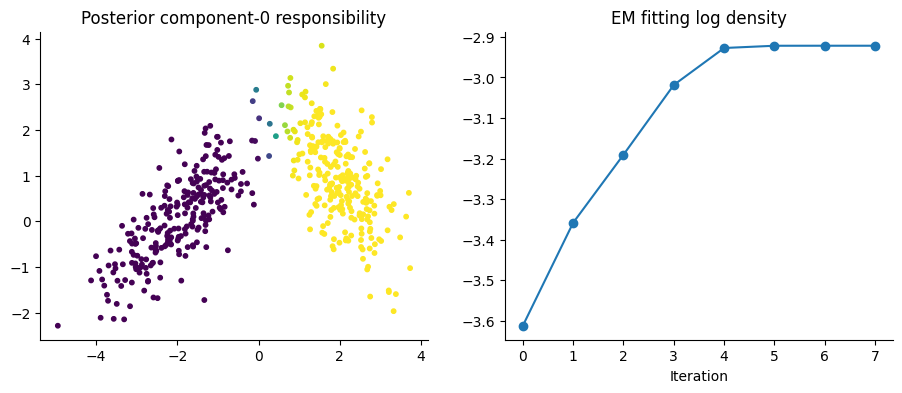

In [3]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(x[:,0], x[:,1], c=r[:,0], s=10, cmap='viridis')
axes[0].set_title('Posterior component-0 responsibility')
axes[1].plot(model.history_, 'o-'); axes[1].set_title('EM fitting log density')
axes[1].set_xlabel('Iteration'); plt.show()

## Density and latent labels answer different questions
BIC is a training likelihood penalty, held-out NLL measures density prediction,
and ARI measures a partition's match with external labels. Inspect all three.

In [4]:
metrics = evidence('probabilistic')
display(pd.DataFrame(metrics['mixture_selection']))
display(pd.Series(metrics['heldout_nll']))
display(pd.Series(metrics['ari']))
print('Wine descriptive stability:', np.mean(metrics['wine']['bootstrap_stability_ari']))

,k,bic,heldout_nll
0,1,25321.130713,4.521053
1,2,21498.646142,3.858680
2,3,19142.289196,3.446219
3,4,19194.055481,3.449054
4,5,19234.246964,3.452507
5,6,19284.055369,3.455076


custom_em     3.446242
sklearn_em    3.446219
dtype: float64

gmm       0.992754
kmeans    0.915396
dtype: float64

Wine descriptive stability: 0.9348150027432128


## Exercise and worked answer
Why should responsibilities sum to one even when densities are tiny? They are
normalized conditional component probabilities. Log-domain normalization avoids
underflow in the density calculation. A covariance floor keeps factorization
defined, but multiple starts and held-out assessment are still needed for a
nonconvex mixture. Component indices have no intrinsic ordering.